# Hands-on exercise

In this simple example you are required to perform a simple linear regression with scipy. Find all the information on the function in the documentation: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html

### Assignment

1) Load the provided .csv file with the used car data

2) Use a linear regression to estimate the car prices from the year, kilometers or engine power. You can make a simple 1D regression from each one of the parameters independently (as an optional task you can also try a 2D or 3D regression combining multiple cues)

3) Firstly perform the estimation using the scipy linregress function (or alternatively you can use the sklearn.linear_model.LinearRegression class).
NB: check the documentation of the two methods!! In particular be aware of the number of outputs (in case use "_" to avoid the return of a specific output).

4) Have a look at the correlation coefficient to see which of the 3 features works better

5) Then implement the least square algorithm: you should get exactly the same solution of linregress !

6) Plot the data and the lines representing the output of the linregress and least square algorithms


In [1]:
# FORNITO DAL PROF

import matplotlib.pyplot as plt
import csv
from scipy import stats
import numpy as np
import sklearn as sl
from sklearn import linear_model

In [2]:
# FORNITO DAL PROF

# Load the provided data file with the used car data (you can also have a look at it with any text editor)

filename = "data/km_year_power_price.csv"
lines = csv.reader(open(filename, newline=''), delimiter=',')

##
# place your loading code here
##

In [3]:
# csv.reader non carica i dati in memoria. 
# Restituisce un iteratore: ogni volta che lo scorri ti dà una riga del file come lista di stringhe, per esempio ['32500', '2012', '110', '9500']
# Provando infatti a stampare si ottiene (l'iteratore si può scorrere una volta sola, una volta stampato risulta vuoto, bisogna trovare allora un altro modo)

# a ogni giro "line" è una sola riga di stringhe 
#for line in lines:
#    print(line)  #stampa una alla volta tutte le stringhe

# Quindi i valori che ho sono stringhe e non numeri, prima cosa che voglio fare è trasformare i dati in float:

# Dividiamo la cosa in passi

#1
#############################

# Trasformo subito l'iteratore in una lista vera con dentro tutte le righe ancora come stringhe
dataset = list(lines)[1:]  # => ora dataset si può scorrere quante volte si vuole (parte dalla seconda riga con [1:], toglie quindi l'intestazione)

print(dataset)

[['125000', '2001', '40', '1371.11'], ['150000', '2001', '40', '1298.70'], ['5000', '2001', '60', '1232.43'], ['50000', '2001', '60', '1733.89'], ['60000', '2001', '60', '1985.24'], ['70000', '2001', '60', '2100.86'], ['80000', '2001', '60', '1473.93'], ['90000', '2001', '60', '1542.09'], ['100000', '2001', '60', '1399.41'], ['125000', '2001', '60', '1365.02'], ['150000', '2001', '60', '1158.64'], ['5000', '2001', '80', '1441.33'], ['30000', '2001', '80', '2717.71'], ['50000', '2001', '80', '2732.83'], ['70000', '2001', '80', '2265.15'], ['80000', '2001', '80', '2141.35'], ['90000', '2001', '80', '2379.50'], ['100000', '2001', '80', '1934.69'], ['125000', '2001', '80', '1838.33'], ['150000', '2001', '80', '1517.53'], ['5000', '2001', '100', '2103.80'], ['30000', '2001', '100', '2186.36'], ['60000', '2001', '100', '3352.86'], ['70000', '2001', '100', '3272.65'], ['80000', '2001', '100', '2928.75'], ['90000', '2001', '100', '2481.43'], ['100000', '2001', '100', '2814.53'], ['125000', '20

In [4]:
#2
#############################
lunghezza = len(dataset)
print("Il dataset iniziale contiene:", lunghezza, "stringhe")

print("")
print("##############")
print("")

# Scorre gli indici delle righe (1, 2, ...) e sostituisce ogni riga con la sua versione numerica:
for i in range(len(dataset)):
    dataset[i] = [float(x) for x in dataset[i]]

print(dataset)

Il dataset iniziale contiene: 1297 stringhe

##############

[[125000.0, 2001.0, 40.0, 1371.11], [150000.0, 2001.0, 40.0, 1298.7], [5000.0, 2001.0, 60.0, 1232.43], [50000.0, 2001.0, 60.0, 1733.89], [60000.0, 2001.0, 60.0, 1985.24], [70000.0, 2001.0, 60.0, 2100.86], [80000.0, 2001.0, 60.0, 1473.93], [90000.0, 2001.0, 60.0, 1542.09], [100000.0, 2001.0, 60.0, 1399.41], [125000.0, 2001.0, 60.0, 1365.02], [150000.0, 2001.0, 60.0, 1158.64], [5000.0, 2001.0, 80.0, 1441.33], [30000.0, 2001.0, 80.0, 2717.71], [50000.0, 2001.0, 80.0, 2732.83], [70000.0, 2001.0, 80.0, 2265.15], [80000.0, 2001.0, 80.0, 2141.35], [90000.0, 2001.0, 80.0, 2379.5], [100000.0, 2001.0, 80.0, 1934.69], [125000.0, 2001.0, 80.0, 1838.33], [150000.0, 2001.0, 80.0, 1517.53], [5000.0, 2001.0, 100.0, 2103.8], [30000.0, 2001.0, 100.0, 2186.36], [60000.0, 2001.0, 100.0, 3352.86], [70000.0, 2001.0, 100.0, 3272.65], [80000.0, 2001.0, 100.0, 2928.75], [90000.0, 2001.0, 100.0, 2481.43], [100000.0, 2001.0, 100.0, 2814.53], [125000.0,

In [5]:
#3
#############################

dataset = np.array(dataset)

print(dataset)

print("")
print("##############")
print("")

print(f"L'array creato ha dimensione: {dataset.ndim} (servono allora {dataset.ndim} indici per individuare un elemento)")
print("(righe, colonne) =", dataset.shape)
print("Le colonne corrispondono a km, anno, potenza, prezzo")

[[1.250000e+05 2.001000e+03 4.000000e+01 1.371110e+03]
 [1.500000e+05 2.001000e+03 4.000000e+01 1.298700e+03]
 [5.000000e+03 2.001000e+03 6.000000e+01 1.232430e+03]
 ...
 [2.000000e+04 2.015000e+03 2.600000e+02 4.949238e+04]
 [1.000000e+04 2.015000e+03 3.000000e+02 3.854269e+04]
 [2.000000e+04 2.015000e+03 3.000000e+02 3.968332e+04]]

##############

L'array creato ha dimensione: 2 (servono allora 2 indici per individuare un elemento)
(righe, colonne) = (1297, 4)
Le colonne corrispondono a km, anno, potenza, prezzo


In [6]:
#4
#############################

# Allora ora fissiamo le colonne separatamente

km = dataset[:, 0]
year = dataset[:, 1]
power = dataset[:, 2]
price = dataset[:, 3]

print("L'array dei km è:", km)
print("L'array degli anni è:", year)
print("L'array della potenza è:", power)
print("L'array del prezzo è:", price)

L'array dei km è: [125000. 150000.   5000. ...  20000.  10000.  20000.]
L'array degli anni è: [2001. 2001. 2001. ... 2015. 2015. 2015.]
L'array della potenza è: [ 40.  40.  60. ... 260. 300. 300.]
L'array del prezzo è: [ 1371.11  1298.7   1232.43 ... 49492.38 38542.69 39683.32]


Use linear regression to estimate the car prices from the year, kilometers or engine power. 
You can make a simple 1D regression from each one of the parameters independently 




In [7]:
# linear regression with linregress (estimate price from YEAR)

# your code.....

# L'idea è quella della retta che passa meglio tra i punti => prezzo = m * x + q

#result = stats.linregress(x, y) # Dove x è la variabile da cui stimiamo, mentre y è quella da stimare

# Il risultato contiene 5 valori (da documentazione)
# 1) slope (pendenza, di quanto cambia il prezzo in funzione di x)
# 2) intercept (il valore della retta per x = 0)
# 3) rvalue (coefficiente di correlazione r, tra -1 e 1)
# 4) pvalue  
# 5) stderr (errore standard sulla pendenza)

# Allora stimiamo il prezzo dall'anno:
result_year = stats.linregress(year, price)

slope_year, intercept_year, r_value_year, _, _ = result_year

# Allora la retta:
price_pred_year = slope_year * year + intercept_year

# stampo:
print("Dalla stima del prezzo dagli anni si ha:")
print(f"Pendenza: {slope_year:.2f}, intercetta: {intercept_year:.2f}, r: {r_value_year:.3f}")

Dalla stima del prezzo dagli anni si ha:
Pendenza: 1509.09, intercetta: -3018309.48, r: 0.677


In [8]:
# (Optional) linear regression with linear_model.LinearRegression() (estimate price from year)
# Recall that in Python a mx1 matrix is different from a 1D array -> need to reshape

# your code.....

In [9]:
# (Optional) perform linear regression with a manually implemented least squares (estimate price from year)
# You should get exactly the same solution of linregress !

# your code.....

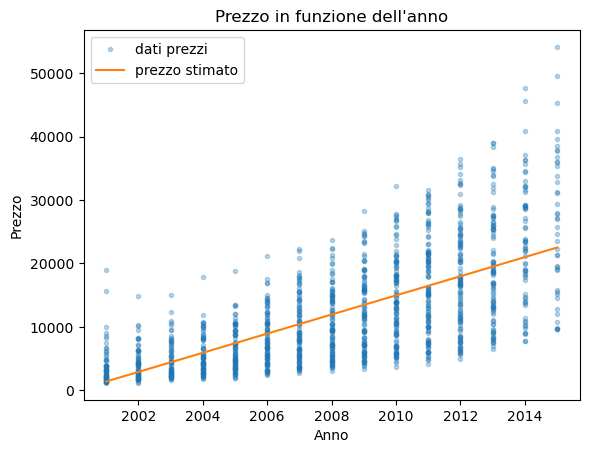

In [10]:
# Plot the data and the lines representing the output of the linregress and least square algorithms

# your code....

plt.plot(year, price, 'o', markersize=3, alpha=0.3,label='dati prezzi')
plt.plot(year, price_pred_year, label='prezzo stimato')
plt.xlabel("Anno")
plt.ylabel("Prezzo")
plt.title("Prezzo in funzione dell'anno")
plt.legend()
plt.show()

In [11]:
# linear regression with linregress (estimate price from power)

# your code.....

# Allora stimiamo il prezzo dalla potenza:
result_power = stats.linregress(power, price)

slope_power, intercept_power, r_value_power, _, _ = result_power

# Allora la retta:
price_pred_power = slope_power * power + intercept_power

# stampo:
print("Dalla stima del prezzo dalla potenza si ha:")
print(f"Pendenza: {slope_power:.2f}, intercetta: {intercept_power:.2f}, r: {r_value_power:.3f}")

Dalla stima del prezzo dalla potenza si ha:
Pendenza: 90.33, intercetta: -1303.91, r: 0.709


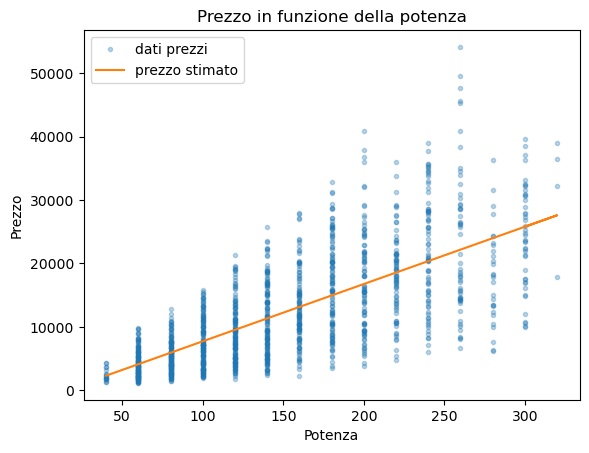

In [12]:
plt.plot(power, price, 'o', markersize=3, alpha=0.3,label='dati prezzi')
plt.plot(power, price_pred_power, label='prezzo stimato')
plt.xlabel("Potenza")
plt.ylabel("Prezzo")
plt.title("Prezzo in funzione della potenza")
plt.legend()
plt.show()

In [13]:
# linear regression with linregress (estimate price from km)

# your code...

# Allora stimiamo il prezzo dai chilometri:
result_km = stats.linregress(km, price)

slope_km, intercept_km, r_value_km, _, _ = result_km

# Allora la retta:
price_pred_km = slope_km * km + intercept_km

# stampo:
print("Dalla stima del prezzo dai km si ha:")
print(f"Pendenza: {slope_km:.2f}, intercetta: {intercept_km:.2f}, r: {r_value_km:.3f}")

Dalla stima del prezzo dai km si ha:
Pendenza: -0.05, intercetta: 16692.35, r: -0.257


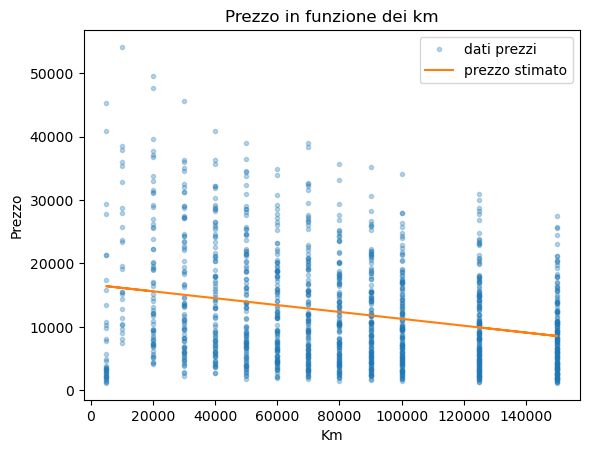

In [14]:
plt.plot(km, price, 'o', markersize=3, alpha=0.3,label='dati prezzi')
plt.plot(km, price_pred_km, label='prezzo stimato')
plt.xlabel("Km")
plt.ylabel("Prezzo")
plt.title("Prezzo in funzione dei km")
plt.legend()
plt.show()

In [15]:
# Have a look at the correlation coefficients to see which of the 3 features works better

# your code......

print(f"Anno:     r = {r_value_year:.3f}")
print(f"Potenza:  r = {r_value_power:.3f}")
print(f"Km:       r = {r_value_km:.3f}")

# La variable con valore assoluto del coeff di correlazione maggiore è la varbiale che predice meglio il prezzo

abs_year = abs(r_value_year)
abs_power = abs(r_value_power)
abs_km = abs(r_value_km)

massimo = max(abs_year, abs_power, abs_km) # max da il numero non il nome della variabile

if massimo == abs_year:
    migliore = "anno"
elif massimo == abs_power:
    migliore = "potenza"
else:
    migliore = "km"

print(f"La varaibile che predice meglio il prezzo è: {migliore}")

Anno:     r = 0.677
Potenza:  r = 0.709
Km:       r = -0.257
La varaibile che predice meglio il prezzo è: potenza


In [16]:
# (Optional) 2D linear regression with linear model (estimate price from year and power)


# your code......
